<a href="https://colab.research.google.com/github/felipe-suarez06/Validando-hip-tesis-de-negocio-con-pruebas-estad-sticas/blob/main/S9_Version_Student_Proyecto_Landing_Experiment_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [ ]:
# importar librerías
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from scipy.stats import ttest_ind
from scipy.stats import levene
from statsmodels.stats.proportion import proportions_ztest


In [ ]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [ ]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [ ]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


-El dataset no presenta valores ausentes.
-La columna date es de tipo object y debería ser de tipo date.

In [ ]:
#se procede a la corrección de tipo de dato en date
df["date"] = pd.to_datetime(df["date"])

In [ ]:
#comprobación de corrección
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   user_id         40000 non-null  object        
 1   date            40000 non-null  datetime64[ns]
 2   landing         40000 non-null  object        
 3   region          40000 non-null  object        
 4   dispositivo     40000 non-null  object        
 5   traffic_source  40000 non-null  object        
 6   user_type       40000 non-null  object        
 7   converted       40000 non-null  int64         
 8   gasto           40000 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 2.7+ MB


**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [ ]:
df["user_id"].nunique()

40000

 **Variable `date`**  
Explorar rango de fechas

In [ ]:
# Resumen estadístico
df["date"].describe()

count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [ ]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [ ]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [ ]:
# Resumen estadístico de usuarios que se convirtieron
df["converted"].describe()

count    40000.00000
mean         0.14265
std          0.34972
min          0.00000
25%          0.00000
50%          0.00000
75%          0.00000
max          1.00000
Name: converted, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [ ]:
# Explorar variables categóricas y cómo se distribuyen

print("\nConteo de categorías:")
print(df["landing"].value_counts())
print()
print(df["region"].value_counts())
print()
print(df["dispositivo"].value_counts())
print()
print(df["traffic_source"].value_counts())
print()
print(df["user_type"].value_counts())



Conteo de categorías:
B    20018
A    19982
Name: landing, dtype: int64

Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


Hallazgos:
Todas las columnas tienen valores esperados, es decir, no hay errores .

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [ ]:
# Gasto por versión
gasto_A = df[df["landing"] == "A"]["gasto"] #completa el código
gasto_B = df[df["landing"] == "B"]["gasto"] #completa el código

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(19982, 20018)

In [ ]:
print(gasto_B.head())
print()
gasto_A.head()

2     0.00
5     0.00
7     0.00
8     0.00
9    27.61
Name: gasto, dtype: float64



0    38.08
1     0.00
3     0.00
4     0.00
6     0.00
Name: gasto, dtype: float64

Tanto en la página A como en la página B, no todos los usuarios se convirtieron o compraron, por lo que aplicaremos un filtro que incluya solo a los que sí convirtieron.

In [ ]:
# Gasto por versión de los que sí convirtieron

gasto_A = df[(df["landing"] == "A") & (df["converted"]== 1)]["gasto"]
gasto_B = df[(df["landing"] == "B")& (df["converted"]== 1)]["gasto"]

print(gasto_A.head())
print()
print(gasto_B.head())
print()
print("Gasto promedio A:", round(gasto_A.mean(),3))
print("Gasto promedio B:", round(gasto_B.mean(),3))

0      38.08
17     42.97
27    119.26
44     74.26
45     61.56
Name: gasto, dtype: float64

9      27.61
25     70.59
30     57.38
62    109.20
65     97.77
Name: gasto, dtype: float64

Gasto promedio A: 61.087
Gasto promedio B: 68.745


### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** el gasto promedio de los usuarios convertidos en A es igual al de B
- **Hipótesis alternativa (H₁):** los gastos promedio son diferentes.

In [ ]:
#Prueba de Levene (test de varianzas)
#Hipótesis:
#•	H₀ (hipótesis nula): las varianzas de los grupos son iguales.
#•	H₁ (hipótesis alterna): las varianzas de los grupos son diferentes.

# Ejecutar prueba de Levene y mostrar resultados
l_stat, p_value_var = levene(gasto_A,gasto_B)

print(f"Estadístico de Levene: {l_stat}")
print(f"Valor p: {p_value_var}")
print()

alpha = 0.05  # umbral de significancia

if p_value_var < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia de varianzas diferentes (equal_var=True).")


Estadístico de Levene: 29.17646453202917
Valor p: 6.875301988016449e-08

Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).


In [ ]:
# Aplicar prueba

t_stat,p_value = ttest_ind(gasto_A,gasto_B,equal_var=False)

# Visualizar resultados
print(f"Estadístico : {t_stat}")
print(f"Valor p: {p_value}")

Estadístico : -9.48101092267275
Valor p: 3.627602231521493e-21


In [ ]:
alpha = 0.05  # umbral de significancia

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")


Rechazamos la hipótesis nula: hay evidencia de una diferencia.


### 📝 Conclusión e interpretación

**Decisión:**  
Rechazamos la hipótesis nula.

**Interpretación de negocio:**  

Dado que se calculó ttest_ind(gasto_A, gasto_B), el signo negativo en el valor del estadístico indica que el gasto promedio de la página A es menor que el de la página B, esto solo por el orden de la comparación.
El valor de p_value al ser menor de 0.05, indica que hay evidencia estadística significativa para rechazar la hipótesis nula, reafirmando la diferencia en el gasto promedio de cada página.

Este resultado se basa en una muestra de usuarios que realizaron una compra y no evalúa si la diferencia observada es suficiente para justificar un cambio desde una perspectiva de negocio.


---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalúa si existen diferencias estadísticamente significativas en la **tasa de conversión** entre las páginas A y B, con el fin de identificar qué versión genera un **mayor número de usuarios convertidos**.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** la tasa de conversión de A es igual a la de B.
- **Hipótesis alternativa (H₁):** la tasa de conversión de A es diferente a la de B.

In [ ]:
# Número de usuarios convertidos por página

conversiones = df.groupby("landing")["converted"].sum()

# Total de usuarios por página

totales = df.groupby("landing")["converted"].count()


print(f"Usuarios convertidos por página:\n", conversiones)
print(f"\nTotal de usuarios por página:\n", totales)

Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [ ]:
#organizando los datos en listas:
#número de éxitos
exitos = [conversiones["A"], conversiones["B"]]
print(exitos)

#total de observaciones por grupo.
observaciones = [totales["A"], totales["B"]]
print(observaciones)

[2512, 3194]
[19982, 20018]


In [ ]:
# Aplicar prueba
z_stats, p_value = proportions_ztest(exitos,observaciones)

# Visualizar resultados
print(f"Estadístico : {z_stats}")
print(f"Valor p: {p_value}")

Estadístico : -9.677362674655983
Valor p: 3.7629765627523803e-22


In [ ]:
alpha = 0.05  # umbral de significancia

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")


Rechazamos la hipótesis nula: hay evidencia de una diferencia.


In [ ]:
#cálculo de cual página convierte mejor

tasa_A = exitos[0] / observaciones[0]

tasa_B = exitos[1] / observaciones[1]

print(f"Tasa de conversión página A: {tasa_A:.2%}")
print(f"Tasa de conversión página B: {tasa_B:.2%}")

Tasa de conversión página A: 12.57%
Tasa de conversión página B: 15.96%


### 📝 Conclusión e interpretación

**Decisión:**  
Rechazamos la hipótesis nula

**Interpretación de negocio:**  


Con base en una prueba z para proporciones, encontramos evidencia estadística de una diferencia en la tasa de conversión entre las páginas A y B.
En particular, la página B muestra una tasa de conversión mayor que la página A, aproximadamente 3.39 puntos porcentuales a favor de B..

Este resultado se basa en una muestra de usuarios y no evalúa si la magnitud de la diferencia es suficiente para justificar una decisión de negocio.”


## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):**  traffic_source y converted son independientes.
- **Hipótesis alternativa (H₁):** existe asociación entre traffic_source y converted.

In [ ]:

#tabla de contingencia

tabla = pd.crosstab(df["traffic_source"],df["converted"])
tabla


converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


In [ ]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)


In [ ]:
print(f"Estadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)
print()
alpha = 0.05  # umbral de significancia

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")
print()

#tabla de contingencia normalizada

tabla_normalizada = pd.crosstab(df["traffic_source"],df["converted"],normalize="index")*100
tabla_normalizada




Estadístico chi-cuadrado: 8.662
Valor P: 0.034
Grados de libertad: 3

Frecuencias esperadas:
[[10232.47225  1702.52775]
 [ 5249.55405   873.44595]
 [15421.15445  2565.84555]
 [ 3390.81925   564.18075]]

Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.



converted,0,1
traffic_source,,
Ads,85.261835,14.738165
Email,85.007349,14.992651
Organic,86.212264,13.787736
Referral,86.118837,13.881163


### 📝 Conclusión e interpretación

**Decisión:**  
Rechazamos la hipótesis

**Interpretación de negocio:**  

Con base en el test de independencia(chi2), encontramos evidencia estadística de que la conversión está asociada al canal por el que llegó el usuario”.
En particular, los usuarios que llegaron mediante el canal de email muestran una mayor tasa de conversión que los de Ads, Organic y Referral. Sin embargo, la diferencia entre los porcentajes de conversión es muy baja, lo que indica que en términos prácticos, una diferencia de 1-2 puntos porcentuales en conversión entre canales no es algo sobre lo que el negocio deba tomar decisiones drásticas (como invertir mucho más en un canal y abandonar otro).

## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** user_type y converted son independientes.
- **Hipótesis alternativa (H₁):** existe asociación entre user_type y converted.

In [ ]:
#tabla de contingencia

tabla = pd.crosstab(df["user_type"],df["converted"])
tabla


converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


In [ ]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

In [ ]:
print(f"Estadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)
print()
alpha = 0.05  # umbral de significancia

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")
print()
#tabla de contingencia normalizada

tabla_normalizada = pd.crosstab(df["user_type"],df["converted"],normalize="index")*100
tabla_normalizada

Estadístico chi-cuadrado: 0.513
Valor P: 0.474
Grados de libertad: 1

Frecuencias esperadas:
[[22319.39255  3713.60745]
 [11974.60745  1992.39255]]

No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.



converted,0,1
user_type,,
Nuevo,85.641301,14.358699
Recurrente,85.909644,14.090356


### 📝 Conclusión e interpretación

**Decisión:**  
No rechazamos la hipótesis nula

**Interpretación de negocio:**  

No rechazamos la hipótesis nula, es decir, no hay evidencia que demuestre asociación entre user_type y converted, reforzando esta decisión con la tabla de porcentajes donde Nuevo=14.35% y Recurrente= 14.09%, donde prácticamente son similares.
Este resultado se basa en una muestra de usuarios y no implica causalidad directa ni evalúa si esta diferencia justifica decisiones diferenciadas desde una perspectiva de negocio.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

In [ ]:

#tabla de contingencia

tabla = pd.crosstab(df["traffic_source"],df["converted"])
tabla


converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


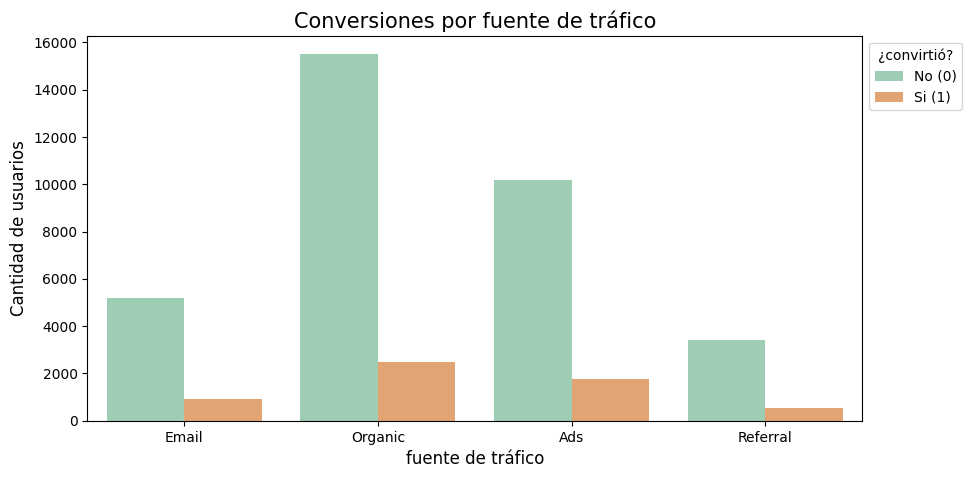

In [ ]:
# Gráfico de barras agrupadas
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="traffic_source", hue="converted", palette = ["#95D5B2", "#F4A261"])

# Añadir detalles
plt.title("Conversiones por fuente de tráfico", fontsize=15)
plt.xlabel("fuente de tráfico", fontsize=12)
plt.ylabel("Cantidad de usuarios", fontsize=12)
plt.legend(title="¿convirtió?",labels=["No (0)","Si (1)"], loc="upper left", bbox_to_anchor=(1,1))
plt.show()





Este gráfico muestra la cantidad de usuarios que convirtieron y no convirtieron según el tipo de fuente de tráfico.
Observamos que Organic y Ads concentran la mayoría del volumen, mientras que Email y Referral tienen una participación baja. De igual forma podemos observar que a pesar de tener una mayor cantidad de usuarios que convirtieron en la fuente de tráfico orgánic y ads, también presentan el mayor número de usuarios que no convirtieron
El gráfico muestra volumen pero no permite ver directamente las tasas de conversión.

In [ ]:
#tabla de contingencia normalizada

tabla_normalizada = pd.crosstab(df["traffic_source"],df["converted"],normalize="index")*100
tabla_normalizada


converted,0,1
traffic_source,,
Ads,85.261835,14.738165
Email,85.007349,14.992651
Organic,86.212264,13.787736
Referral,86.118837,13.881163


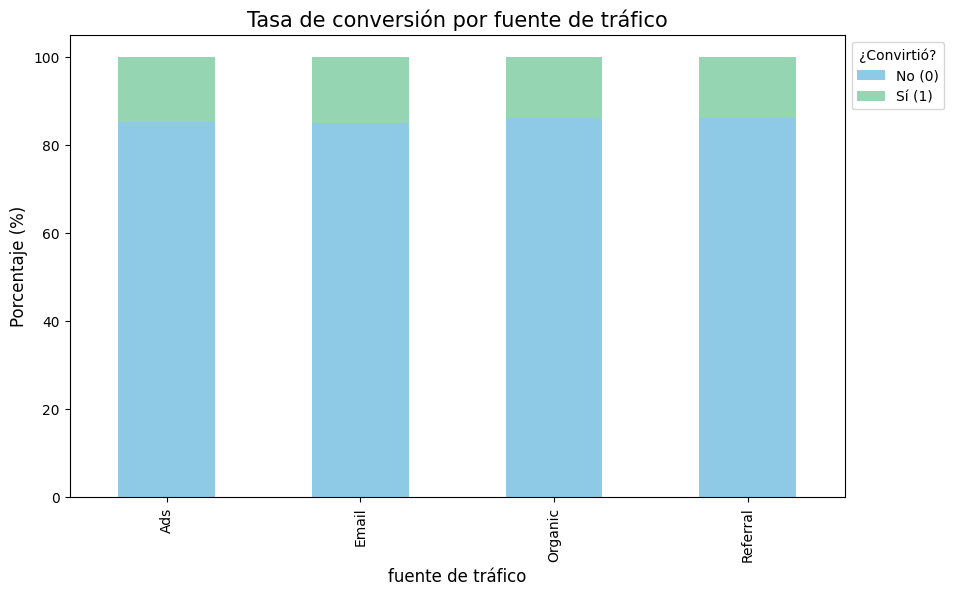

In [ ]:
# Gráfica de barras apiladas
tabla_normalizada.plot(kind="bar", stacked=True, figsize=(10, 6), color=["#8ecae6", "#95d5b2"])

plt.title("Tasa de conversión por fuente de tráfico", fontsize=15)
plt.ylabel("Porcentaje (%)", fontsize=12)
plt.xlabel("fuente de tráfico", fontsize=12)
plt.legend(title="¿Convirtió?", labels=["No (0)", "Sí (1)"], loc="upper left", bbox_to_anchor=(1, 1))
plt.show()


Este gráfico muestra la tasa de usuarios que convirtieron y no convirtieron según el tipo de fuente de tráfico.
La diferencia en las tasas de conversión tanto de los que sí convirtieron como de los que no, visualmente, no es muy perceptible; son muy parecidas.
Confirmando lo que se obtuvo en los cálculos, aunque hay una diferencia estadísticamente significativa, las tasas reales son muy parecidas entre fuentes.

### Relación entre el tipo de usuario y la conversión

In [ ]:
#tabla de contingencia

tabla = pd.crosstab(df["user_type"],df["converted"])
tabla


converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


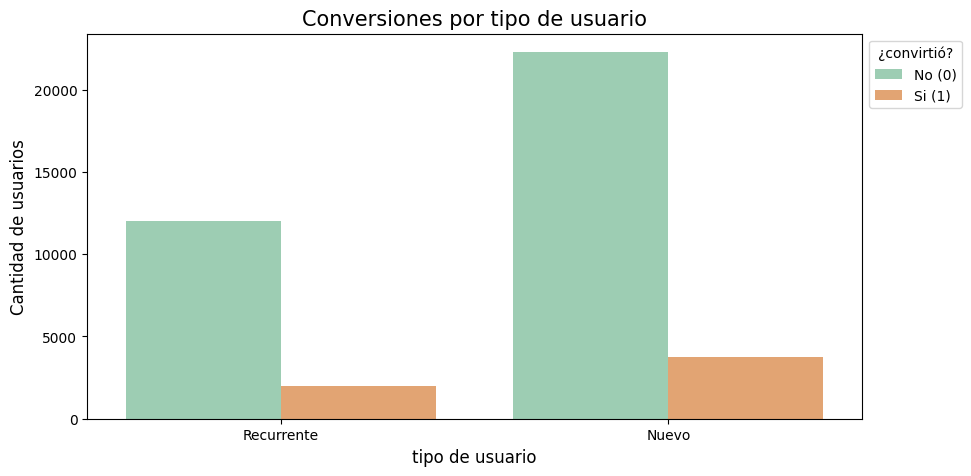

In [ ]:
# Gráfico de barras agrupadas
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="user_type", hue="converted", palette = ["#95D5B2", "#F4A261"])

# Añadir detalles
plt.title("Conversiones por tipo de usuario", fontsize=15)
plt.xlabel("tipo de usuario", fontsize=12)
plt.ylabel("Cantidad de usuarios", fontsize=12)
plt.legend(title="¿convirtió?",labels=["No (0)","Si (1)"], loc="upper left", bbox_to_anchor=(1,1))
plt.show()

Este gráfico muestra la cantidad de usuarios que convirtieron y no convirtieron según el tipo de usuario.
Observamos que Nuevo concentra la mayoría del volumen, mientras que Recurrente tiene una participación más baja.
El gráfico muestra volumen pero no permite ver directamente las tasas de conversión.

In [ ]:
#tabla de contingencia normalizada

tabla_normalizada = pd.crosstab(df["user_type"],df["converted"],normalize="index")*100
tabla_normalizada

converted,0,1
user_type,,
Nuevo,85.641301,14.358699
Recurrente,85.909644,14.090356


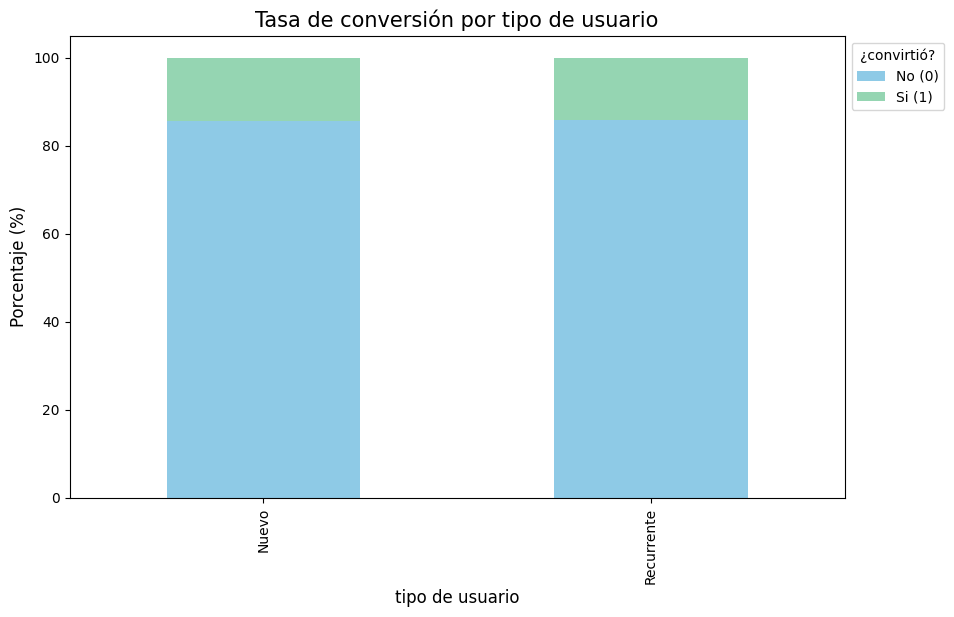

In [ ]:
# Gráfica de barras apiladas
tabla_normalizada.plot(kind="bar", stacked=True, figsize=(10, 6), color=["#8ecae6", "#95d5b2"])

plt.title("Tasa de conversión por tipo de usuario", fontsize=15)
plt.ylabel("Porcentaje (%)", fontsize=12)
plt.xlabel("tipo de usuario", fontsize=12)
plt.legend(title="¿convirtió?",labels=["No (0)","Si (1)"], loc="upper left", bbox_to_anchor=(1,1))
plt.show()



Este gráfico muestra la tasa de usuarios que convirtieron y no convirtieron según el tipo de usuario.
La diferencia en las tasas de conversión tanto de los que sí convirtieron como de los que no, visualmente, no es muy perceptible; son muy parecidas.
Confirmando lo que se obtuvo en los cálculos, aunque no hay evidencia que demuestre asociación entre user_type y converted, las tasas reales son muy parecidas entre tipo de usuario.



## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?

  --la página B presenta mayor conversión y gasto promedio
  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?

  --Los canales Email y ads, resultaron más efectivos.
  
- ¿Existen diferencias significativas según el tipo de usuario?

  --De acuerdo con los resultados, no se encontró diferencia significativa.
  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?
  
  -- Priorizar la página B como candidata para implementación, validar su rendimiento en un despliegue gradual y monitorear que se mantenga estable.

  
  -- Probar optimizaciones en Email y Ads: Email tuvo la mayor tasa de conversión (14.99%) y Ads quedó cerca (14.74%). Ejecutar pruebas específicas en mensajes, ofertas y páginas de destino; no reasignar drásticamente el presupuesto solo por estas pequeñas diferencias.

  -- Evaluar los canales por rentabilidad, no solo por conversión: comparar costo de adquisición, ingresos y retorno de la inversión por canal. Organic y Ads aportaron más conversiones en volumen, pero eso no indica por sí solo cuál es más rentable.

  -- Mantener una estrategia similar para usuarios nuevos y recurrentes: sus tasas fueron muy parecidas y no se encontró una diferencia estadísticamente significativa por tipo de usuario. Seguir monitoreando los segmentos antes de crear campañas separadas.


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- La prueba de ttest detectó una diferencia estadísticamente significativa entre las páginas (p_value = 3.63 x 10(-21))
- El estadístico fue negativo al comparar página A menos página B, lo que indica que el gasto promedio de los usuarios convertidos fue menor en A que en B.
- **Interpretación:**
Entre quienes convirtieron, la página B presentó un gasto promedio mayor. El resultado respalda que existe una diferencia entre las páginas.
Gasto promedio A: 61.087
Gasto promedio B: 68.745
<br>

**Tasa de conversión:**
- La página A convirtió el 12.57% de sus usuarios (2,512 de 19,982).
- La página B convirtió el 15.96% (3,194 de 20,018). La diferencia fue estadísticamente significativa (prueba z: p = 3.76 × 10⁻²²).
- **Interpretación:**
-La página B tuvo una tasa de conversión mayor que A, con una diferencia de aproximadamente 3.39 puntos porcentuales. Los resultados favorecen a B en conversión.
---

#### 📊 **Segmentación por fuente de tráfico**
- Email presentó la mayor tasa de conversión (14.99%), seguido de Ads (14.74%), Referral (13.88%) y Organic (13.79%). Organic y Ads concentraron el mayor volumen de usuarios y conversiones. La asociación entre canal y conversión fue estadísticamente significativa (chi2 = 8.662, p = 0.034), aunque las tasas difieren poco.
- **Interpretación:**

  --- Email fue el canal más eficiente por tasa en estos datos, pero la brecha respecto de Ads fue pequeña. Conviene evaluar los canales tanto por tasa como por volumen, costo e ingresos antes de reasignar presupuesto; la significancia estadística por sí sola no demuestra que el impacto sea comercialmente importante.

#### 📊 **Segmentación por tipo de usuario**
- La conversión fue de 14.36% para usuarios nuevos y de 14.09% para recurrentes. No se encontró evidencia estadísticamente significativa de asociación entre tipo de usuario y conversión (chi2 = 0.513, p = 0.474).
- **Interpretación:**

  --- Las tasas son muy similares y los datos no respaldan estrategias distintas de conversión basadas únicamente en este tipo de usuario.

  Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

  --- Las gráficas sí respaldan los resultados estadísticos.

#### 💡 **Recomendaciones de negocio:**
- Priorizar la página B como candidata para implementación, pues mostró mayor conversión y mayor gasto promedio entre quienes convirtieron.
- Optimizar los canales de forma gradual: probar mejoras en Email y Ads, y evaluar cada canal por conversión, volumen, costo de adquisición e ingreso, sin abandonar canales por diferencias pequeñas de tasa.
- No crear campañas diferenciadas solo por tipo de usuario con base en estos resultados; primero se necesitaría evidencia más clara de una diferencia relevante.